# Interpretable Regression Baselines and Diagnostics for Robot Arm Inverse Dynamics

DS-A3 reproducible single-output regression study. The notebook contains the analysis steps directly; small shared utilities for validation, metrics, error slices, and PDF layout are documented in scripts/analysis_helpers.py.

The original SARCOS test file is excluded from predictive modeling because it overlaps substantially with the training matrix. The frozen blocked and random indices are used unchanged.

## 1. Research Question and Hypotheses

How accurately can interpretable regularized linear models predict first-joint torque from the robotic arm's kinematic state, and under which observed conditions do predictions become less reliable?

Inputs are seven joint positions, seven velocities, and seven accelerations (columns 0–20). The target is first-joint torque (column 21, zero-based); the other torque columns are excluded.

- H1: OLS improves predictive performance over a training-mean Dummy Regressor.
- H2: Ridge may improve or stabilize generalization, but need not outperform OLS.
- H3: Errors vary across velocity, acceleration, and torque-magnitude conditions.

Inference is limited to held-out rows from this matrix. Blocked evaluates a held-out contiguous region; Random evaluates observations held out from the mixed source distribution. Neither establishes episode-independent, new-task, or new-robot performance.

## 2. Dataset Loading and Provenance

The local MATLAB files were downloaded from the public GitHub repository [Kaixhin/SARCOS](https://github.com/Kaixhin/SARCOS), which contains both named files. The upstream dataset description is available from [Gaussian Processes for Machine Learning](https://gaussianprocess.org/gpml/data/) and credits Sethu Vijayakumar. The repository's software license is not treated as a data license. Physical units are not asserted.

In [1]:
from pathlib import Path
import json, platform, sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy, sklearn
from IPython.display import display
from scipy.io import loadmat
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge

project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "data/raw/sarcos_inv.mat").exists():
    project_root = project_root.parent
if not (project_root / "data/raw/sarcos_inv.mat").exists():
    raise FileNotFoundError("Run from the project or notebooks directory.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from scripts.analysis_helpers import (
    ALPHA_GRID, EXPECTED_COUNTS, dataset_sha256, feature_names,
    make_test_error_slices, scaled_pipeline, score_regression,
    verify_frozen_indices, write_pdf_report,
)

data_path = project_root / "data/raw/sarcos_inv.mat"
test_file_path = project_root / "data/raw/sarcos_inv_test.mat"
split_path = project_root / "data/splits/sarcos_split_indices.npz"
manifest_path = project_root / "data/splits/sarcos_split_manifest.json"
results_path = project_root / "reports/analysis_results.json"
historical_results_path = project_root / "reports/pre_refactor_analysis_results.json"
figures_dir = project_root / "reports/figures"
figures_dir.mkdir(parents=True, exist_ok=True)
manifest = json.loads(manifest_path.read_text())
data_hash = dataset_sha256(data_path)
assert data_hash == manifest["data_file_sha256"]
matrix = loadmat(data_path)["sarcos_inv"]
assert matrix.shape == (44484, 28)
assert np.issubdtype(matrix.dtype, np.number) and np.isfinite(matrix).all()
X, y = matrix[:, :21], matrix[:, 21]
feature_labels = feature_names()
data = pd.DataFrame(
    matrix,
    columns=feature_labels + [f"joint_{i}_torque" for i in range(1, 8)],
)
environment = {
    "Python": platform.python_version(), "NumPy": np.__version__,
    "pandas": pd.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.DataFrame([
    ["Training matrix", 44484, "28 numeric columns"],
    ["Predictors", 44484, "columns 0–20"],
    ["Target", 44484, "column 21, first torque"],
    ["Original test matrix (excluded)", loadmat(test_file_path)["sarcos_inv_test"].shape[0], "leakage evidence only"],
], columns=["Item", "Rows", "Description"]))
display(pd.Series({"Dataset SHA256": data_hash, **environment}, name="Verified metadata").to_frame())

,Item,Rows,Description
0,Training matrix,44484,28 numeric columns
1,Predictors,44484,columns 0–20
2,Target,44484,"column 21, first torque"
3,Original test matrix (excluded),4449,leakage evidence only


,Verified metadata
Dataset SHA256,b8a249733253ba6097372fedee7696833fcf30de42037d...
Python,3.10.18
NumPy,2.2.6
pandas,2.3.1
SciPy,1.15.2
scikit-learn,1.7.1


## 3. Data Quality and Exploratory Analysis

Report missing and infinite values, duplicate and constant rows/columns, target summary, representative feature distributions, and sampled predictor correlations. The heatmap uses 2,500 evenly spaced source rows for a readable descriptive view.

,Check,Result
0,Shape,"(44484, 28)"
1,Dtypes,float64
2,Missing,0
3,Infinite,0
4,Duplicate full rows,0
5,Duplicate input rows,0
6,Constant columns,None


,First-joint torque
Statistic,
count,44484.000000
mean,13.653835
std,20.464791
min,-94.876411
25%,1.087409
50%,12.810330
75%,25.825956
max,121.381996


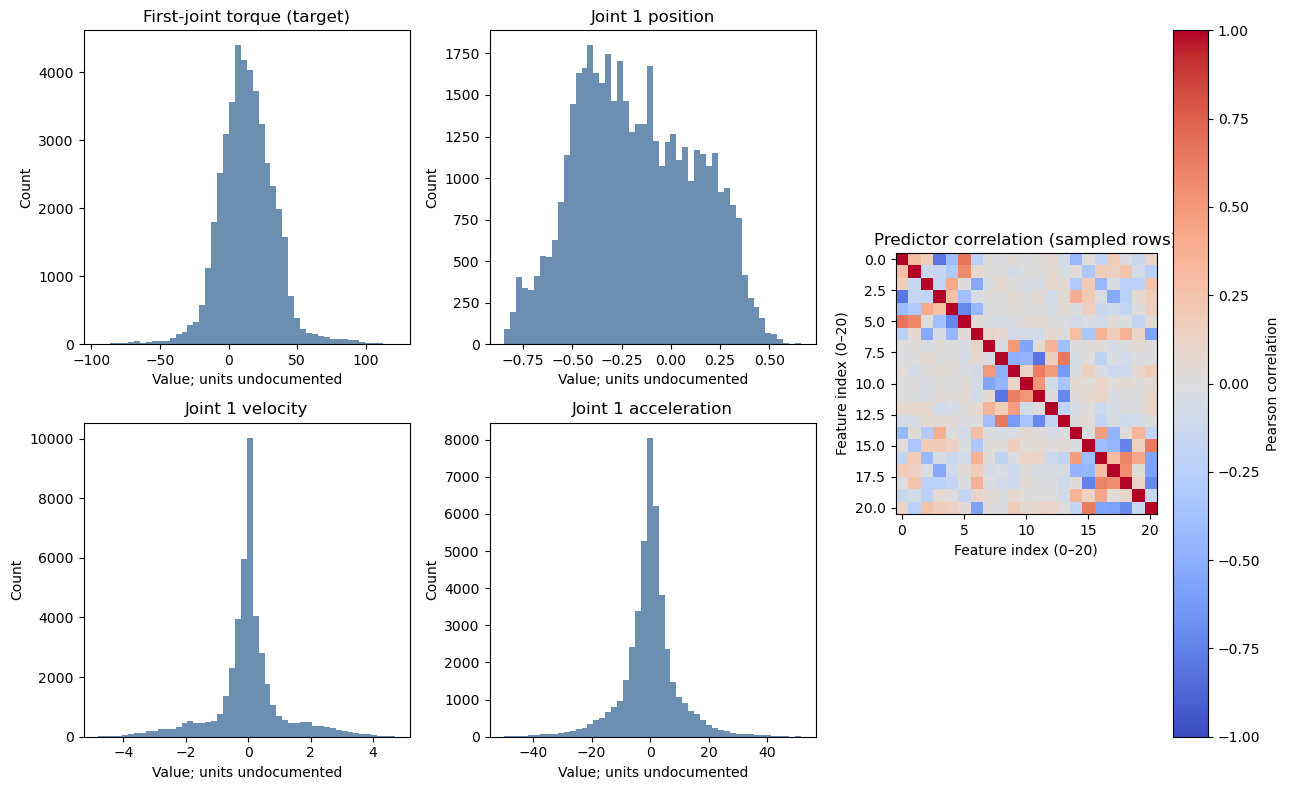

In [2]:
quality_table = pd.DataFrame({
    "Check": ["Shape", "Dtypes", "Missing", "Infinite", "Duplicate full rows",
              "Duplicate input rows", "Constant columns"],
    "Result": [
        str(data.shape), ", ".join(sorted(data.dtypes.astype(str).unique())),
        int(data.isna().sum().sum()), int(np.isinf(matrix).sum()),
        int(data.duplicated().sum()), int(data.iloc[:, :21].duplicated().sum()),
        ", ".join(data.columns[data.nunique(dropna=False) <= 1]) or "None",
    ],
})
display(quality_table)
display(pd.Series(y).describe().rename_axis("Statistic").to_frame("First-joint torque"))

fig = plt.figure(figsize=(13, 8))
grid = fig.add_gridspec(2, 3)
axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1]),
        fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]
for axis, values, title in zip(
    axes,
    [y, matrix[:, 0], matrix[:, 7], matrix[:, 14]],
    ["First-joint torque (target)", "Joint 1 position", "Joint 1 velocity", "Joint 1 acceleration"],
):
    axis.hist(values, bins=50, color="#527aa3", alpha=.85)
    axis.set(title=title, xlabel="Value; units undocumented", ylabel="Count")
sample_rows = np.linspace(0, len(X)-1, 2500, dtype=int)
correlation_axis = fig.add_subplot(grid[:, 2])
image = correlation_axis.imshow(np.corrcoef(X[sample_rows].T), vmin=-1, vmax=1, cmap="coolwarm")
correlation_axis.set(title="Predictor correlation (sampled rows)",
                     xlabel="Feature index (0–20)", ylabel="Feature index (0–20)")
fig.colorbar(image, ax=correlation_axis, label="Pearson correlation")
fig.tight_layout()
eda_figure = figures_dir / "exploration.png"
fig.savefig(eda_figure, dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Frozen Split Verification

Use the existing index archive and manifest as the split authority. Counts are Blocked 26,665 / 8,847 / 8,872 and Random 26,690 / 8,897 / 8,897 (seed 42). Partition distribution summaries are descriptive and do not tune models. The Blocked protocol is not a verified episode-independent split; no reliable episode identifiers are available, and the 25-row purge does not guarantee independence.

In [3]:
with np.load(split_path) as archive:
    frozen_indices = {key: archive[key].copy() for key in archive.files}
split_audit = verify_frozen_indices(frozen_indices, manifest, len(matrix))
display(split_audit)

for protocol, parts in EXPECTED_COUNTS.items():
    for part in parts:
        idx = frozen_indices[f"{protocol}_{part}"].astype(int)
        assert np.array_equal(X[idx], matrix[idx, :21])
        assert np.array_equal(y[idx], matrix[idx, 21])

distribution_rows = []
for protocol, parts in EXPECTED_COUNTS.items():
    for part in parts:
        idx = frozen_indices[f"{protocol}_{part}"].astype(int)
        xp, yp = X[idx], y[idx]
        distribution_rows.append({
            "Protocol": protocol.title(), "Partition": part.title(), "n": len(idx),
            "Target mean": yp.mean(), "Target SD": yp.std(),
            "Median velocity norm": np.median(np.linalg.norm(xp[:, 7:14], axis=1)),
            "Median acceleration norm": np.median(np.linalg.norm(xp[:, 14:21], axis=1)),
        })
split_distribution_table = pd.DataFrame(distribution_rows)
display(split_distribution_table.round(4))

,Protocol,Partition,Count,Minimum row,Maximum row
0,Blocked,Train,26665,0,26664
1,Blocked,Val,8847,26715,35561
2,Blocked,Test,8872,35612,44483
3,Random,Train,26690,2,44476
4,Random,Val,8897,1,44483
5,Random,Test,8897,0,44481


,Protocol,Partition,n,Target mean,Target SD,Median velocity norm,Median acceleration norm
0,Blocked,Train,26665,13.3676,22.4450,2.3018,21.9614
1,Blocked,Val,8847,15.6105,18.8061,0.3636,5.4212
2,Blocked,Test,8872,12.6192,15.0209,2.2242,24.6873
3,Random,Train,26690,13.5860,20.5637,2.0344,19.6477
4,Random,Val,8897,13.9716,20.3342,2.0266,19.4187
5,Random,Test,8897,13.5394,20.2927,2.0118,19.4866


## 5. Dummy and OLS Baselines

Fit the training-mean Dummy Regressor and OLS on Blocked Train. OLS preprocessing uses a StandardScaler inside a Pipeline, fitted only on Train. Show Validation MAE, RMSE, and R-squared.

In [4]:
blocked_train_idx = frozen_indices["blocked_train"].astype(int)
blocked_val_idx = frozen_indices["blocked_val"].astype(int)
blocked_test_idx = frozen_indices["blocked_test"].astype(int)
X_blocked_train, y_blocked_train = X[blocked_train_idx], y[blocked_train_idx]
X_blocked_val, y_blocked_val = X[blocked_val_idx], y[blocked_val_idx]

blocked_dummy_train = DummyRegressor(strategy="mean").fit(X_blocked_train, y_blocked_train)
blocked_ols_train = scaled_pipeline(LinearRegression()).fit(X_blocked_train, y_blocked_train)
blocked_baseline_predictions = {
    "Dummy mean": blocked_dummy_train.predict(X_blocked_val),
    "OLS": blocked_ols_train.predict(X_blocked_val),
}
blocked_baseline_table = pd.DataFrame({
    name: score_regression(y_blocked_val, prediction)
    for name, prediction in blocked_baseline_predictions.items()
}).T.rename_axis("Model")
display(blocked_baseline_table.round(6))

,MAE,RMSE,R2
Model,,,
Dummy mean,14.154144,18.939334,-0.014223
OLS,3.659087,5.175371,0.924267


## 6. Ridge Hyperparameter Selection

Fit the fixed Ridge alpha grid on Blocked Train and select by Blocked Validation MAE. Test labels are not used in alpha selection.

In [5]:
blocked_ridge_candidates = {}
blocked_alpha_rows = []
for alpha in ALPHA_GRID:
    model = scaled_pipeline(Ridge(alpha=alpha)).fit(X_blocked_train, y_blocked_train)
    blocked_ridge_candidates[alpha] = model
    row_metrics = score_regression(y_blocked_val, model.predict(X_blocked_val))
    blocked_alpha_rows.append({"Alpha": alpha, **row_metrics})
blocked_alpha_table = pd.DataFrame(blocked_alpha_rows).set_index("Alpha")
display(blocked_alpha_table.round(8))
blocked_selected_alpha = min(ALPHA_GRID, key=lambda a: (blocked_alpha_table.loc[a, "MAE"], a))
print("Blocked alpha selected by Validation MAE:", blocked_selected_alpha)
blocked_validation_metrics = {
    "Dummy mean": score_regression(y_blocked_val, blocked_baseline_predictions["Dummy mean"]),
    "OLS": score_regression(y_blocked_val, blocked_baseline_predictions["OLS"]),
    "Ridge": score_regression(
        y_blocked_val, blocked_ridge_candidates[blocked_selected_alpha].predict(X_blocked_val)
    ),
}
blocked_validation_table = pd.DataFrame(blocked_validation_metrics).T.rename_axis("Model")
display(blocked_validation_table.round(6))

,MAE,RMSE,R2
Alpha,,,
0.001,3.659089,5.175373,0.924267
0.010,3.659107,5.175390,0.924266
0.100,3.659291,5.175561,0.924261
1.000,3.661130,5.177273,0.924211
10.000,3.679262,5.194288,0.923712
100.000,3.838380,5.353417,0.918966
1000.000,4.697640,6.402110,0.884109


Blocked alpha selected by Validation MAE: 0.001


,MAE,RMSE,R2
Model,,,
Dummy mean,14.154144,18.939334,-0.014223
OLS,3.659087,5.175371,0.924267
Ridge,3.659089,5.175373,0.924267


## 7. Random Protocol Validation and Independent Tuning

Use separate Random Train scaling and models. Select Random Ridge alpha independently from Random Validation MAE. Together with Blocked tuning, this freezes all model configurations before final Test evaluation.

In [6]:
random_train_idx = frozen_indices["random_train"].astype(int)
random_val_idx = frozen_indices["random_val"].astype(int)
random_test_idx = frozen_indices["random_test"].astype(int)
X_random_train, y_random_train = X[random_train_idx], y[random_train_idx]
X_random_val, y_random_val = X[random_val_idx], y[random_val_idx]

random_dummy_train = DummyRegressor(strategy="mean").fit(X_random_train, y_random_train)
random_ols_train = scaled_pipeline(LinearRegression()).fit(X_random_train, y_random_train)
random_ridge_candidates = {}
random_alpha_rows = []
for alpha in ALPHA_GRID:
    model = scaled_pipeline(Ridge(alpha=alpha)).fit(X_random_train, y_random_train)
    random_ridge_candidates[alpha] = model
    row_metrics = score_regression(y_random_val, model.predict(X_random_val))
    random_alpha_rows.append({"Alpha": alpha, **row_metrics})
random_alpha_table = pd.DataFrame(random_alpha_rows).set_index("Alpha")
display(random_alpha_table.round(8))
random_selected_alpha = min(ALPHA_GRID, key=lambda a: (random_alpha_table.loc[a, "MAE"], a))
random_validation_metrics = {
    "Dummy mean": score_regression(y_random_val, random_dummy_train.predict(X_random_val)),
    "OLS": score_regression(y_random_val, random_ols_train.predict(X_random_val)),
    "Ridge": score_regression(
        y_random_val, random_ridge_candidates[random_selected_alpha].predict(X_random_val)
    ),
}
display(pd.DataFrame(random_validation_metrics).T.rename_axis("Model").round(6))
print("Random alpha selected by Validation MAE:", random_selected_alpha)

,MAE,RMSE,R2
Alpha,,,
0.001,3.946146,5.546013,0.925611
0.010,3.946147,5.546013,0.925611
0.100,3.946156,5.546013,0.925611
1.000,3.946249,5.546017,0.925611
10.000,3.947221,5.546143,0.925607
100.000,3.961893,5.554299,0.925388
1000.000,4.218416,5.870540,0.916650


,MAE,RMSE,R2
Model,,,
Dummy mean,15.327958,20.337810,-0.000360
OLS,3.946146,5.546013,0.925611
Ridge,3.946146,5.546013,0.925611


Random alpha selected by Validation MAE: 0.001


## 8. Freeze Diagnostic Choices Before Final Test

Residual is actual minus predicted, so positive residuals indicate underprediction. The predeclared diagnostics are actual-versus-predicted, residual-versus-predicted, residual distribution, and absolute error against velocity norm, acceleration norm, and absolute target. Error-slice quartiles are derived from Blocked Train only.

In [7]:
slice_thresholds = {
    "Velocity norm": np.unique(np.quantile(
        np.linalg.norm(X_blocked_train[:, 7:14], axis=1), [0, .25, .5, .75, 1]
    )),
    "Acceleration norm": np.unique(np.quantile(
        np.linalg.norm(X_blocked_train[:, 14:21], axis=1), [0, .25, .5, .75, 1]
    )),
    "Absolute target": np.unique(np.quantile(
        np.abs(y_blocked_train), [0, .25, .5, .75, 1]
    )),
}
display(pd.DataFrame([
    {"Slice variable": name, "Train-derived edges": ", ".join(f"{v:.6g}" for v in values)}
    for name, values in slice_thresholds.items()
]))
print("Residual definition: actual - predicted; positive values mean underprediction.")

,Slice variable,Train-derived edges
0,Velocity norm,"0.0124019, 1.44069, 2.30176, 2.99481, 6.32166"
1,Acceleration norm,"0.169779, 13.8308, 21.9614, 31.1808, 91.175"
2,Absolute target,"0, 7.11475, 15.3596, 28.7719, 120.974"


Residual definition: actual - predicted; positive values mean underprediction.


## 9. Final Evaluation on Frozen Test Partitions

Both protocols' models and alphas are now fixed. Final estimators and scalers are refit on Train + Validation for each protocol. Test targets first enter predictive scoring here and are used only for final evaluation and subsequent diagnostics. They do not affect fitting, scaling, tuning, thresholds, or redesign.

In [8]:
protocol_configs = {
    "Blocked": {
        "train_idx": blocked_train_idx, "val_idx": blocked_val_idx,
        "test_idx": blocked_test_idx, "alpha": blocked_selected_alpha,
        "validation": blocked_validation_metrics,
    },
    "Random": {
        "train_idx": random_train_idx, "val_idx": random_val_idx,
        "test_idx": random_test_idx, "alpha": random_selected_alpha,
        "validation": random_validation_metrics,
    },
}
final_models, final_predictions, test_metrics, test_arrays = {}, {}, {}, {}
for protocol, config in protocol_configs.items():
    fit_idx = np.concatenate([config["train_idx"], config["val_idx"]])
    test_idx = config["test_idx"]
    X_fit, y_fit = X[fit_idx], y[fit_idx]
    X_test_protocol, y_test_protocol = X[test_idx], y[test_idx]
    models = {
        "Dummy mean": DummyRegressor(strategy="mean"),
        "OLS": scaled_pipeline(LinearRegression()),
        "Ridge": scaled_pipeline(Ridge(alpha=config["alpha"])),
    }
    final_models[protocol] = models
    final_predictions[protocol], test_metrics[protocol] = {}, {}
    test_arrays[protocol] = (X_test_protocol, y_test_protocol)
    for model_name, model in models.items():
        model.fit(X_fit, y_fit)
        prediction = model.predict(X_test_protocol)
        final_predictions[protocol][model_name] = prediction
        test_metrics[protocol][model_name] = score_regression(y_test_protocol, prediction)

metric_rows = []
for protocol, config in protocol_configs.items():
    for partition, model_metrics in [
        ("Validation", config["validation"]), ("Test", test_metrics[protocol])
    ]:
        for model, values in model_metrics.items():
            metric_rows.append({"Protocol": protocol, "Partition": partition, "Model": model, **values})
metrics_table = pd.DataFrame(metric_rows)
display(metrics_table.round(6))

,Protocol,Partition,Model,MAE,RMSE,R2
0,Blocked,Validation,Dummy mean,14.154144,18.939334,-0.014223
1,Blocked,Validation,OLS,3.659087,5.175371,0.924267
2,Blocked,Validation,Ridge,3.659089,5.175373,0.924267
3,Blocked,Test,Dummy mean,11.631207,15.077691,-0.007574
4,Blocked,Test,OLS,3.864966,5.339591,0.873636
5,Blocked,Test,Ridge,3.864966,5.339591,0.873636
6,Random,Validation,Dummy mean,15.327958,20.337810,-0.000360
7,Random,Validation,OLS,3.946146,5.546013,0.925611
8,Random,Validation,Ridge,3.946146,5.546013,0.925611
9,Random,Test,Dummy mean,15.306403,20.293163,-0.000050


## 10. Residual Diagnostics

These plots describe Blocked Test residuals from the final Blocked Ridge model. They are not used to change model settings. Patterns are interpreted cautiously because the contiguous region may differ from training and episode identifiers are unavailable.

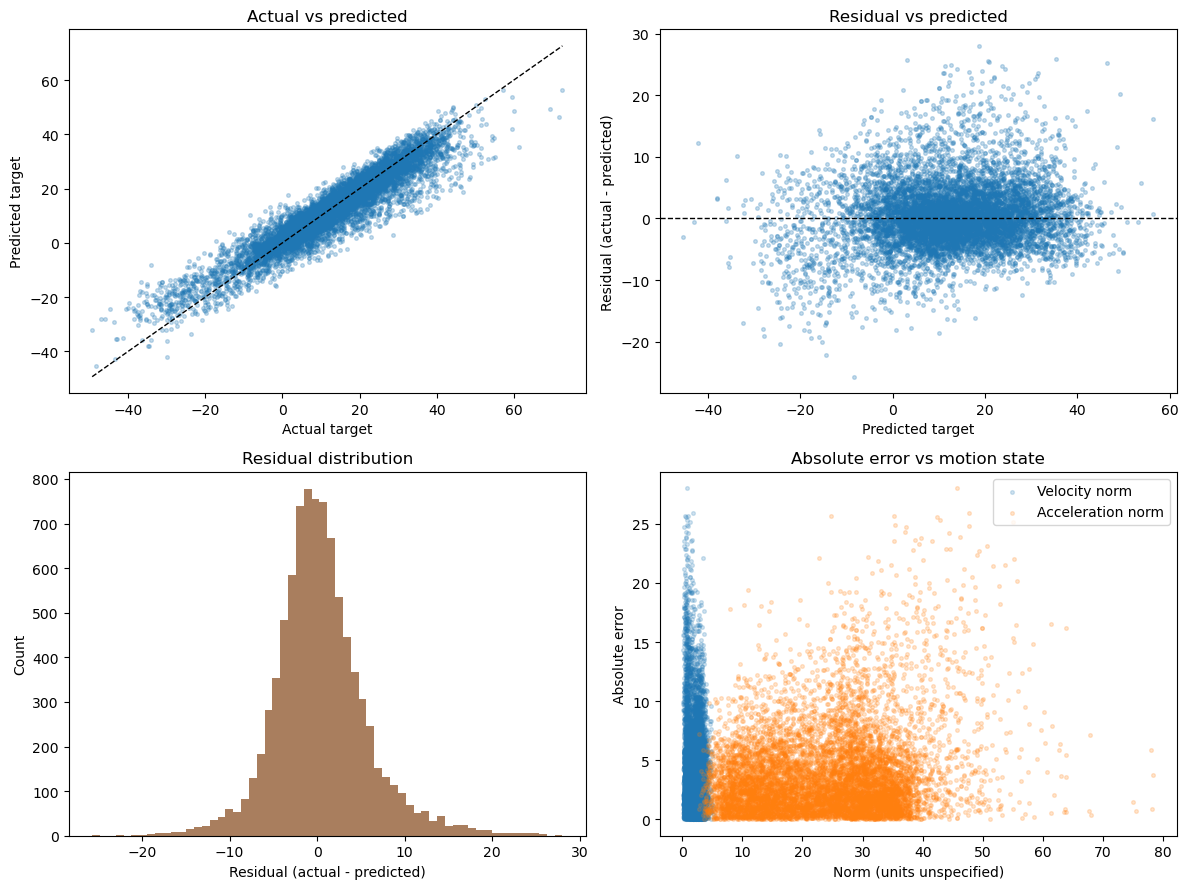

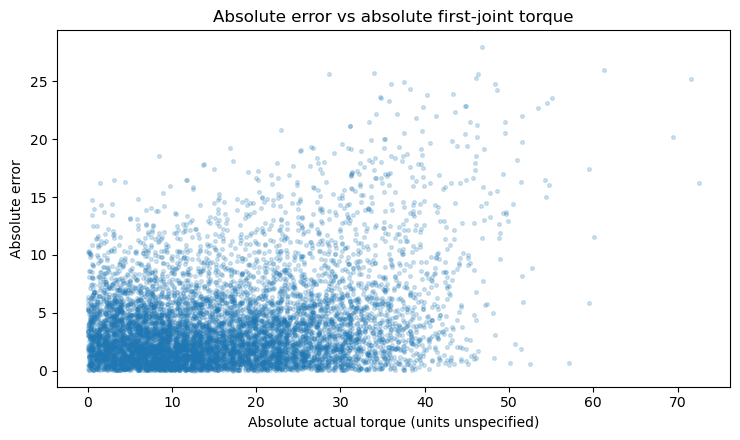

Blocked Ridge residual mean=0.421291; SD=5.322945


In [9]:
X_blocked_test, y_blocked_test = test_arrays["Blocked"]
blocked_test_prediction = final_predictions["Blocked"]["Ridge"]
blocked_test_residual = y_blocked_test - blocked_test_prediction
blocked_test_abs_error = np.abs(blocked_test_residual)
blocked_test_velocity_norm = np.linalg.norm(X_blocked_test[:, 7:14], axis=1)
blocked_test_acceleration_norm = np.linalg.norm(X_blocked_test[:, 14:21], axis=1)
blocked_test_abs_torque = np.abs(y_blocked_test)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].scatter(y_blocked_test, blocked_test_prediction, s=7, alpha=.25)
limits = [min(y_blocked_test.min(), blocked_test_prediction.min()),
          max(y_blocked_test.max(), blocked_test_prediction.max())]
axes[0, 0].plot(limits, limits, "k--", linewidth=1)
axes[0, 0].set(title="Actual vs predicted", xlabel="Actual target", ylabel="Predicted target")
axes[0, 1].scatter(blocked_test_prediction, blocked_test_residual, s=7, alpha=.25)
axes[0, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0, 1].set(title="Residual vs predicted", xlabel="Predicted target",
               ylabel="Residual (actual - predicted)")
axes[1, 0].hist(blocked_test_residual, bins=60, color="#9a6842", alpha=.85)
axes[1, 0].set(title="Residual distribution", xlabel="Residual (actual - predicted)", ylabel="Count")
axes[1, 1].scatter(blocked_test_velocity_norm, blocked_test_abs_error, s=7, alpha=.2,
                   label="Velocity norm")
axes[1, 1].scatter(blocked_test_acceleration_norm, blocked_test_abs_error, s=7, alpha=.2,
                   label="Acceleration norm")
axes[1, 1].set(title="Absolute error vs motion state",
               xlabel="Norm (units unspecified)", ylabel="Absolute error")
axes[1, 1].legend()
fig.tight_layout()
diagnostic_figure = figures_dir / "blocked_test_diagnostics.png"
fig.savefig(diagnostic_figure, dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axis = plt.subplots(figsize=(7.5, 4.5))
axis.scatter(blocked_test_abs_torque, blocked_test_abs_error, s=7, alpha=.2)
axis.set(title="Absolute error vs absolute first-joint torque",
         xlabel="Absolute actual torque (units unspecified)", ylabel="Absolute error")
fig.tight_layout()
torque_error_figure = figures_dir / "error_vs_torque.png"
fig.savefig(torque_error_figure, dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Blocked Ridge residual mean={blocked_test_residual.mean():.6f}; "
      f"SD={blocked_test_residual.std():.6f}")

## 11. Error Slices

Apply the fixed Blocked Train quartile cutoffs to Blocked Test without changing the existing bin assignments. The first and last labels are open-ended so observations below the training minimum or above the maximum are correctly represented. The table reports the number outside the training min/max for each slicing variable. Coincident quantile boundaries are collapsed before digitizing; the table reports the effective number of resulting slices. Each slice reports count, MAE, RMSE, and mean signed residual.

In [10]:
slice_table, serialized_slices = make_test_error_slices(
    X_blocked_train, y_blocked_train,
    X_blocked_test, y_blocked_test,
    blocked_test_prediction,
)
display(slice_table.round(6))

,Slice variable,Slice interval (train-derived cutoffs),n,Outside training min/max,Effective slices after duplicate cutoffs,MAE,RMSE,Mean signed residual
0,Velocity norm,"(-inf, 1.44069]",2552,0,4,4.696993,6.646502,0.757316
1,Velocity norm,"(1.44069, 2.30176]",2110,0,4,3.589645,4.970201,0.407023
2,Velocity norm,"(2.30176, 2.99481]",2366,0,4,3.445624,4.517212,0.447499
3,Velocity norm,"(2.99481, +inf)",1844,0,4,3.566569,4.646547,-0.061053
4,Acceleration norm,"(-inf, 13.8308]",1922,0,4,3.132738,4.062080,-0.229417
5,Acceleration norm,"(13.8308, 21.9614]",1891,0,4,3.518306,4.605684,0.284516
6,Acceleration norm,"(21.9614, 31.1808]",2624,0,4,4.095413,5.492264,-0.343564
7,Acceleration norm,"(31.1808, +inf)",2435,0,4,4.463808,6.471302,1.865349
8,Absolute target,"(-inf, 7.11475]",2210,0,4,3.291983,4.234127,-1.054526
9,Absolute target,"(7.11475, 15.3596]",2541,0,4,3.162787,4.262764,-0.226889


## 12. Split Sensitivity and Standardized Coefficients

Compare Random and Blocked results while keeping model families, metrics, alpha candidates, and final-fit policy fixed. Differences can arise from temporal dependence, local sample similarity, and distribution shift; they do not alone establish leakage.

Standardized OLS and Ridge coefficients are shown for descriptive comparison. Correlated features mean they are not separately identified physical parameters.

In [11]:
sensitivity_table = metrics_table.pivot_table(
    index=["Partition", "Model"], columns="Protocol", values=["MAE", "RMSE", "R2"]
)
display(sensitivity_table.round(6))
alpha_selection_table = pd.DataFrame([
    {"Protocol": "Blocked", "Selected alpha": blocked_selected_alpha,
     "Validation MAE": blocked_alpha_table.loc[blocked_selected_alpha, "MAE"]},
    {"Protocol": "Random", "Selected alpha": random_selected_alpha,
     "Validation MAE": random_alpha_table.loc[random_selected_alpha, "MAE"]},
])
display(alpha_selection_table.round(8))

ols_coef = final_models["Blocked"]["OLS"].named_steps["model"].coef_
ridge_coef = final_models["Blocked"]["Ridge"].named_steps["model"].coef_
coefficient_table = pd.DataFrame({
    "Feature": feature_labels,
    "OLS coefficient": ols_coef,
    "Ridge coefficient": ridge_coef,
})
coefficient_table["Absolute OLS"] = coefficient_table["OLS coefficient"].abs()
coefficient_table["Absolute Ridge"] = coefficient_table["Ridge coefficient"].abs()
coefficient_table = coefficient_table.sort_values("Absolute OLS", ascending=False)
display(coefficient_table.head(12).round(6))
display(pd.DataFrame({
    "Mean absolute standardized coefficient": {
        "OLS": np.mean(np.abs(ols_coef)), "Ridge": np.mean(np.abs(ridge_coef))
    }
}).round(6))

MAE                   R2                 RMSE  \
Protocol                 Blocked     Random   Blocked    Random    Blocked   
Partition  Model                                                             
Test       Dummy mean  11.631207  15.306403 -0.007574 -0.000050  15.077691   
           OLS          3.864966   3.947145  0.873636  0.924658   5.339591   
           Ridge        3.864966   3.947145  0.873636  0.924658   5.339591   
Validation Dummy mean  14.154144  15.327958 -0.014223 -0.000360  18.939334   
           OLS          3.659087   3.946146  0.924267  0.925611   5.175371   
           Ridge        3.659089   3.946146  0.924267  0.925611   5.175373   

                                  
Protocol                  Random  
Partition  Model                  
Test       Dummy mean  20.293163  
           OLS          5.570033  
           Ridge        5.570033  
Validation Dummy mean  20.337810  
           OLS          5.546013  
           Ridge        5.546013

,Protocol,Selected alpha,Validation MAE
0,Blocked,0.001,3.659089
1,Random,0.001,3.946146


,Feature,OLS coefficient,Ridge coefficient,Absolute OLS,Absolute Ridge
14,joint_1_acceleration,26.177958,26.177952,26.177958,26.177952
17,joint_4_acceleration,9.752945,9.752939,9.752945,9.752939
0,joint_1_position,8.755539,8.755530,8.755539,8.755530
3,joint_4_position,-2.774787,-2.774795,2.774787,2.774795
4,joint_5_position,2.040137,2.040137,2.040137,2.040137
5,joint_6_position,1.967198,1.967202,1.967198,1.967202
16,joint_3_acceleration,-1.913488,-1.913486,1.913488,1.913486
15,joint_2_acceleration,-1.746639,-1.746639,1.746639,1.746639
18,joint_5_acceleration,-1.369372,-1.369372,1.369372,1.369372
2,joint_3_position,-1.181943,-1.181945,1.181943,1.181945


,Mean absolute standardized coefficient
OLS,2.973380
Ridge,2.973379


## 13. Discussion and Conclusion

Conclusions below are calculated from the executed metrics and error slices. The primary finding concerns prediction on the supplied matrix under these frozen partitions. It does not establish transfer to independent episodes, unseen tasks, or another robot.

In [12]:
blocked_test_metrics = test_metrics["Blocked"]
blocked_val_metrics = protocol_configs["Blocked"]["validation"]
acceleration_slice_mae = slice_table.loc[
    slice_table["Slice variable"] == "Acceleration norm", "MAE"
].tolist()
torque_slice_mae = slice_table.loc[
    slice_table["Slice variable"] == "Absolute target", "MAE"
].tolist()
velocity_slice_mae = slice_table.loc[
    slice_table["Slice variable"] == "Velocity norm", "MAE"
].tolist()
all_slice_mae = slice_table["MAE"].dropna().to_numpy()
velocity_differences = np.diff(velocity_slice_mae)
velocity_is_non_monotonic = not (
    np.all(velocity_differences >= 0) or np.all(velocity_differences <= 0)
)
assert velocity_is_non_monotonic
assert velocity_slice_mae[0] > velocity_slice_mae[-1]

interpretation = [
    (f"H1 supported on Blocked Test: OLS MAE ({blocked_test_metrics['OLS']['MAE']:.3f}) "
     f"is lower than Dummy MAE ({blocked_test_metrics['Dummy mean']['MAE']:.3f})."),
    (f"H2: Blocked Validation selected alpha={blocked_selected_alpha}; Ridge and OLS "
     f"validation MAE are {blocked_val_metrics['Ridge']['MAE']:.3f} and "
     f"{blocked_val_metrics['OLS']['MAE']:.3f}. The lack of meaningful Ridge improvement "
     "applies only to these tested models, this alpha grid, this dataset, and these evaluation protocols."),
    (f"H3: high-acceleration Blocked Test MAE ({acceleration_slice_mae[-1]:.3f}) exceeds "
     f"low-acceleration MAE ({acceleration_slice_mae[0]:.3f}); high-absolute-torque MAE "
     f"({torque_slice_mae[-1]:.3f}) exceeds low-absolute-torque MAE ({torque_slice_mae[0]:.3f}). "
     f"Velocity-slice MAEs by increasing quartile are {[round(v, 3) for v in velocity_slice_mae]}; "
     f"they are non-monotonic, and low-velocity MAE ({velocity_slice_mae[0]:.3f}) exceeds "
     f"highest-velocity MAE ({velocity_slice_mae[-1]:.3f}). These are descriptive patterns; "
     "no physical mechanism is inferred."),
    (f"Random Test OLS MAE is {test_metrics['Random']['OLS']['MAE']:.3f}, compared with "
     f"{test_metrics['Blocked']['OLS']['MAE']:.3f} for Blocked Test. They represent different "
     "holdout conditions; this difference alone does not identify its cause."),
]
for conclusion in interpretation:
    print(conclusion)
print(
    "Limitations: temporal dependence, no verified episode IDs, distribution shift, linear-model "
    "assumptions, and unverified data units/license constrain generalization."
)

H1 supported on Blocked Test: OLS MAE (3.865) is lower than Dummy MAE (11.631).
H2: Blocked Validation selected alpha=0.001; Ridge and OLS validation MAE are 3.659 and 3.659. The lack of meaningful Ridge improvement applies only to these tested models, this alpha grid, this dataset, and these evaluation protocols.
H3: high-acceleration Blocked Test MAE (4.464) exceeds low-acceleration MAE (3.133); high-absolute-torque MAE (6.177) exceeds low-absolute-torque MAE (3.292). Velocity-slice MAEs by increasing quartile are [4.697, 3.59, 3.446, 3.567]; they are non-monotonic, and low-velocity MAE (4.697) exceeds highest-velocity MAE (3.567). These are descriptive patterns; no physical mechanism is inferred.
Random Test OLS MAE is 3.947, compared with 3.865 for Blocked Test. They represent different holdout conditions; this difference alone does not identify its cause.
Limitations: temporal dependence, no verified episode IDs, distribution shift, linear-model assumptions, and unverified data un

## 14. Optional Historical Consistency Check

A pre-refactor results snapshot is retained for development auditing, but this notebook does not require it. When present, this retrospective check compares metrics, selected Ridge alphas, training-derived slice thresholds, counts, and slice metrics. It does not affect fitting, model selection, or conclusions. If the snapshot is absent, the check reports that it was skipped.

In [13]:
results_by_protocol = {}
for protocol, config in protocol_configs.items():
    alpha_table = blocked_alpha_table if protocol == "Blocked" else random_alpha_table
    results_by_protocol[protocol.lower()] = {
        "validation": config["validation"],
        "test": test_metrics[protocol],
        "selected_ridge_alpha": config["alpha"],
        "ridge_validation_mae_by_alpha": {
            str(alpha): float(alpha_table.loc[alpha, "MAE"]) for alpha in ALPHA_GRID
        },
    }

revised_results = {
    "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "scikit_learn": sklearn.__version__,
    "dataset_sha256": data_hash,
    "data_quality": {
        "shape": list(matrix.shape), "dtypes": sorted(set(data.dtypes.astype(str))),
        "missing": int(data.isna().sum().sum()), "infinite": int(np.isinf(matrix).sum()),
        "duplicate_rows": int(data.duplicated().sum()),
        "constant_columns": data.columns[data.nunique(dropna=False) <= 1].tolist(),
        "target_describe": data.iloc[:, 21].describe().to_dict(),
    },
    "split_distributions": {
        protocol.lower(): {
            row["Partition"].lower(): {
                "n": row["n"], "target_mean": row["Target mean"], "target_sd": row["Target SD"],
                "velocity_norm_median": row["Median velocity norm"],
                "acceleration_norm_median": row["Median acceleration norm"],
            }
            for row in distribution_rows if row["Protocol"] == protocol
        }
        for protocol in ["Blocked", "Random"]
    },
    "scores": results_by_protocol, "error_slices": serialized_slices,
    "residual_mean": float(blocked_test_residual.mean()),
    "residual_sd": float(blocked_test_residual.std()),
    "interpretation": interpretation,
    "coefficient_abs_mean": {
        "OLS": float(np.mean(np.abs(ols_coef))),
        "Ridge": float(np.mean(np.abs(ridge_coef))),
    },
}

consistency_summary = {"status": "skipped", "reason": "Historical snapshot is not present."}
consistency_table = pd.DataFrame()
if historical_results_path.exists():
    historical_results = json.loads(historical_results_path.read_text())
    consistency_rows = []
    for protocol in ["blocked", "random"]:
        for partition in ["validation", "test"]:
            for model in ["Dummy mean", "OLS", "Ridge"]:
                for metric in ["MAE", "RMSE", "R2"]:
                    old = historical_results["scores"][protocol][partition][model][metric]
                    new = revised_results["scores"][protocol][partition][model][metric]
                    delta = abs(old - new)
                    consistency_rows.append({
                        "Check": f"{protocol}/{partition}/{model}/{metric}",
                        "Original": old, "Revised": new, "Absolute delta": delta,
                        "Pass": bool(np.isclose(old, new, rtol=1e-9, atol=1e-9)),
                    })
            assert historical_results["scores"][protocol]["selected_ridge_alpha"] == \
                   revised_results["scores"][protocol]["selected_ridge_alpha"]

    consistency_table = pd.DataFrame(consistency_rows)
    assert consistency_table["Pass"].all()
    slice_deltas = []
    for variable, old_group in historical_results["error_slices"].items():
        new_group = revised_results["error_slices"][variable]
        assert np.allclose(old_group["training_quartile_edges"],
                           new_group["training_quartile_edges"], rtol=1e-9, atol=1e-9)
        for old_bin, new_bin in zip(old_group["test_bins"], new_group["test_bins"]):
            assert old_bin["n"] == new_bin["n"]
            for metric in ["MAE", "RMSE", "mean_signed_residual"]:
                old_value, new_value = old_bin[metric], new_bin[metric]
                if old_value is None:
                    assert new_value is None
                else:
                    assert np.isclose(old_value, new_value, rtol=1e-9, atol=1e-9)
                    slice_deltas.append(abs(old_value - new_value))

    consistency_summary = {
        "status": "passed",
        "all_validation_and_test_MAE_RMSE_R2_match": bool(consistency_table["Pass"].all()),
        "metric_comparisons": len(consistency_table),
        "maximum_absolute_metric_delta": float(consistency_table["Absolute delta"].max()),
        "selected_alphas_match": True,
        "slice_thresholds_and_counts_match": True,
        "slice_metric_comparisons": len(slice_deltas),
        "maximum_absolute_slice_metric_delta": max(slice_deltas, default=0.0),
        "tolerance": {"rtol": 1e-9, "atol": 1e-9},
    }
    display(consistency_table)
else:
    print("Historical consistency comparison skipped; no historical snapshot is required.")

display(pd.Series(consistency_summary, name="Historical comparison").to_frame())
(project_root / "reports/refactor_consistency_check.json").write_text(
    json.dumps(consistency_summary, indent=2)
)

,Check,Original,Revised,Absolute delta,Pass
0,blocked/validation/Dummy mean/MAE,14.154144,14.154144,0.0,True
1,blocked/validation/Dummy mean/RMSE,18.939334,18.939334,0.0,True
2,blocked/validation/Dummy mean/R2,-0.014223,-0.014223,0.0,True
3,blocked/validation/OLS/MAE,3.659087,3.659087,0.0,True
4,blocked/validation/OLS/RMSE,5.175371,5.175371,0.0,True
5,blocked/validation/OLS/R2,0.924267,0.924267,0.0,True
6,blocked/validation/Ridge/MAE,3.659089,3.659089,0.0,True
7,blocked/validation/Ridge/RMSE,5.175373,5.175373,0.0,True
8,blocked/validation/Ridge/R2,0.924267,0.924267,0.0,True
9,blocked/test/Dummy mean/MAE,11.631207,11.631207,0.0,True


,Historical comparison
status,passed
all_validation_and_test_MAE_RMSE_R2_match,True
metric_comparisons,36
maximum_absolute_metric_delta,0.0
selected_alphas_match,True
slice_thresholds_and_counts_match,True
slice_metric_comparisons,36
maximum_absolute_slice_metric_delta,0.0
tolerance,"{'rtol': 1e-09, 'atol': 1e-09}"


362

## 15. Reproducibility and PDF Export

The PDF is generated from these exact tables and figures and includes conclusions, provenance, model results, error slices, and generalization limitations. Run all commands inside the nussem1 environment.

In [14]:
(project_root / "reports/analysis_results.json").write_text(
    json.dumps(revised_results, indent=2)
)
alpha_report_table = pd.DataFrame({
    "Alpha": ALPHA_GRID,
    "Blocked validation MAE": [blocked_alpha_table.loc[a, "MAE"] for a in ALPHA_GRID],
    "Random validation MAE": [random_alpha_table.loc[a, "MAE"] for a in ALPHA_GRID],
})
coefficient_report_table = coefficient_table[
    ["Feature", "OLS coefficient", "Ridge coefficient"]
].head(12)
write_pdf_report(
    project_root / "reports/DS_A3_report.pdf",
    revised_results, metrics_table, split_distribution_table, alpha_report_table,
    slice_table, coefficient_report_table,
    [eda_figure, diagnostic_figure, torque_error_figure], environment,
)
print("Wrote reports/DS_A3_report.pdf")

Wrote reports/DS_A3_report.pdf


From the project root, activate the documented conda environment and run:

    python scripts/validate_project.py
    jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=600 notebooks/DS_A3_regression_diagnostics.ipynb

The historical numerical snapshot is reports/pre_refactor_analysis_results.json. The full comparison summary is reports/refactor_consistency_check.json.